# 02 – Futuros y cobertura
**Lab #2 – Derivados Financieros** · Puntos 6 a 12 (derivados/cobertura)

## Configuración

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path("..").resolve()              # raíz del repositorio (el notebook corre desde notebooks/)
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))           # permite importar el paquete src/ (src/futuros.py)

from src.futuros import NQ               # especificaciones del contrato NQ (fuente: CME Group)

PROC = RAIZ / "data" / "processed"

## Punto 6 – Número óptimo de contratos (R8 – 7 %)

$$N^* = \frac{\beta_p \cdot V_p}{F_0 \cdot Q_F}$$

| Insumo | Valor | Fuente |
|---|---|---|
| $\beta_p$ | 0,8206 (β **mensual** del portafolio Máx. Sharpe) | Punto 5 |
| $V_p$ | USD 35.000.000 | Enunciado |
| $F_0$ | 28.534,00 (settle del NQZ6 al 30/10/2026) | CME Group – Settlements |
| $Q_F$ | USD 20 por punto del índice | CME Group – Contract Specs (detalle en el Punto 7) |

**β mensual:** Decidimos utilizar la $\beta$ mensual, ya que, las liquidaciones de la cuenta de margen son mensuales (agrupadas por trimestre), y en el punto 4 la exposición a cubrir la definimos como β mensual × $V_0$ ≈ USD 28,72 M. Decidimos mantener la coherencia entre VaR, betas y número de contratos. La $\beta$ diaria la reportamos como referencia.

**Redondeo (discretización):** los contratos son enteros y se redondean **hacia abajo** por lo siguiente:
1. 50.33 está mucho más cerca de 50 que de 51, así que el error es un poco más mínimo que subirlo a 51.
2. Para nuestro caso de la inversión el objetivo es **cubrir, no especular**.

In [2]:
# Punto 6: número óptimo de contratos
Vp = 35_000_000                                   # valor del portafolio (USD)
F0 = NQ["F0"]                                     # settle del NQZ6 al 30/10/2026
betas = {"mensual (elegida)": 0.8206,             # β mensual del portafolio (Punto 5)
         "diaria (referencia)": 0.9304}           # β diaria, solo para comparar

expo_contrato = F0 * NQ["Q_F"]                    # USD que representa un contrato (F0 × Q_F)

for nombre, b in betas.items():
    n_opt = b * Vp / expo_contrato                # N* = βp·Vp / (F0·Q_F)
    print(f"β {nombre}: βp·Vp = {b*Vp:,.0f} USD -> N* = {n_opt:.4f}")

beta_p = betas["mensual (elegida)"]               # beta usada en el resto del laboratorio
N_star = beta_p * Vp / expo_contrato              # número óptimo sin redondear
N      = int(np.floor(N_star))                    # redondeo hacia abajo: cubrir, no especular
razon_cob = N / N_star                            # % de la exposición beta efectivamente cubierta

print(f"\nN* = {N_star:.4f} -> N = {N} contratos CORTOS | razón de cobertura = {razon_cob:.2%}")
print(f"Exposición cubierta = {N*expo_contrato:,.2f} USD | sin cubrir = {beta_p*Vp - N*expo_contrato:,.2f} USD")

β mensual (elegida): βp·Vp = 28,721,000 USD -> N* = 50.3277
β diaria (referencia): βp·Vp = 32,564,000 USD -> N* = 57.0618

N* = 50.3277 -> N = 50 contratos CORTOS | razón de cobertura = 99.35%
Exposición cubierta = 28,534,000.00 USD | sin cubrir = 187,000.00 USD


## Punto 7 – Especificaciones del contrato y posición en futuros (R7 – 6 % · R9 – 10 %)

### 7.1 Especificaciones del contrato

**Plataforma:** CME Group (CME Globex). **Fecha de consulta:** 05/11/2026. Fuentes: [Contract Specs](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.contractSpecs.html), [Margins](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.margins.html), [Settlements](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.settlements.html) y [ficha del contrato (PDF)](https://www.cmegroup.com/trading/equity-index/files/emini-nasdaq-100-futures-options.pdf). Capturas en `docs/referencias/`.

**Elección NQ vs. MNQ:** Para nuestro portafolio que se asemeja a la inversión institucional en este caso USD 35 M decidimos usar el E-mini NQ. Requiere 10 veces menos contratos que el Micro MNQ. Nos decidimos por el NQ, ya que, al requerir menos contrato minimizamos los costos de las comisiones en los 16 roll-overs y además investigando un poco más a fondo nos encontramos con que es el contrato más líquido del Nasdaq-100.

**Mark-to-market:** CME liquida diariamente, pero, el laboratorio supone **liquidación mensual**.

In [3]:
# ---- 7.1 Ficha del contrato (R7) ----
ficha = pd.DataFrame({
    "Especificación": ["Contrato", "Subyacente", "Tamaño (Q_F)", "Tick mínimo", "Valor del tick",
                       "Precio inicial F0 (30/10/2026)", "Vencimientos", "Vencimiento NQZ6",
                       "Liquidación al vencimiento", "Margen de mantenimiento (corto)",
                       "Margen inicial (supuesto)", "Plataforma"],
    "Valor": [NQ["codigo"], NQ["subyacente"], f"USD {NQ['Q_F']} × índice", f"{NQ['tick']} puntos",
              f"USD {NQ['valor_tick']:,.2f} por contrato", f"{NQ['F0']:,.2f}", NQ["vencimientos"],
              NQ["vencimiento"], NQ["liquidacion"], f"USD {NQ['margen_mant']:,.0f} por contrato",
              f"USD {NQ['margen_ini']:,.2f} por contrato (1,10 × VGM)", NQ["plataforma"]],
})
ficha

,Especificación,Valor
0,Contrato,NQZ6
1,Subyacente,Nasdaq-100 (^NDX)
2,Tamaño (Q_F),USD 20 × índice
3,Tick mínimo,0.25 puntos
4,Valor del tick,USD 5.00 por contrato
5,Precio inicial F0 (30/10/2026),"28,534.00"
6,Vencimientos,"mar, jun, sep, dic (tercer viernes)"
7,Vencimiento NQZ6,2026-12-18
8,Liquidación al vencimiento,en efectivo
9,Margen de mantenimiento (corto),"USD 39,407 por contrato"


### 7.2 Márgenes: supuesto del margen inicial

**CME** La página de márgenes de CME solo muestra el **MM** por contrato (USD 39.407 para el NQZ6 en posición corta). El margen inicial se obtiene de la regla del marco establecida por la propia página **CME SPAN 2** ([PDF](https://www.cmegroup.com/clearing/files/cme-span-2-margin-framework.pdf), diapositiva *"Margin Result Breakdown (Continued)"*):

| Tipo de cuenta | Margen inicial |
|---|---|
| Especulativa | $VGI_0 = 1{.}1 \times VGM$ |
| Cobertura (hedge) o miembro | $VGI_0 = VGM$ |

**Supuesto adoptado:** $VGI_0 = 1{.}10 \times VGM =$ **USD 43,347.70 por contrato** Aunque en nuestra inversión adoptemos la entidad de un hedger. Las razones por la que decidimos utilizar este **MI** son:

1. **Coherencia con la notación de clases** (Clase 18: $VGM = VGI_0 \times \%$). Aquí el porcentaje es $1/1{.}10 = 90{.}9\,\%$. Con la regla del hedger que nos ofrece CME no tendríamos alguna pequeña oportunidad a equivocarnos, ya que, los niveles de **MI** y **MM** seían los mismos y cualquier pérdida generaría un llamado al margen.
2. **Fuente oficiales de decisión:** en lugar de tomar un porcentaje arbitrario como lo es el excel de referencia para realizar este ejercicio un 0.5% del ejemplo sería irreal para el NQ.

**MM fijo en USD durante los 4 años** CME publica un margen distinto por vencimiento, en la ruta hay una screenshot `docs/referencias/cme_nq_margins_consulta_2026-11-05.png`, esta tabla es una foto al día de consulta que CME ajusta. Por eso se decidimos mantener el valor del NQZ6 en todos los roll-overs.

**Coherencia temporal** Los márgenes se consultaron el 05/11/2026. Entre el 29/10/2026 y el 05/11/2026 CME no emitió avisos de márgenes de *Equity* los avisos que existen dentro de ese rango de tiempo cubren otras clases de activo así que el valor consultado es el vigente al 30/10/2026.

**Cuenta de margen clases:** En nuestros apuntes en especial la clase 18, si el saldo cae por debajo de $VGM$, hay llamado al margen y se repone **hasta $VGI_0$**.

In [4]:
# 7.2 Márgenes y posición en futuros
VGM_c  = NQ["margen_mant"]                        # VGM por contrato (CME, columna corta)
VGI0_c = NQ["margen_ini"]                         # VGI0 por contrato = 1.10 × VGM (CME SPAN 2)

expo_total = N * expo_contrato                    # exposición total = N × Q_F × F0
VGI0 = N * VGI0_c                                 # garantía inicial total a depositar
VGM  = N * VGM_c                                  # margen de mantenimiento total
apalancamiento = expo_total / VGI0                # veces que la exposición supera la garantía

valor_tick_pos = N * NQ["valor_tick"]             # USD que gana o pierde la posición por tick
holgura_ticks  = (VGI0 - VGM) / valor_tick_pos    # ticks en contra antes de un llamado al margen
holgura_pct    = holgura_ticks * NQ["tick"] / F0  # esa holgura como % del precio del futuro

posicion = pd.Series({
    "beta_p (mensual)": beta_p, "N*": N_star, "N (contratos cortos)": N, "Razón de cobertura": razon_cob,
    "Exposición por contrato (USD)": expo_contrato, "Exposición cubierta (USD)": expo_total,
    "VGI0 por contrato (USD)": VGI0_c, "VGM por contrato (USD)": VGM_c,
    "VGI0 total (USD)": VGI0, "VGM total (USD)": VGM, "Apalancamiento (veces)": apalancamiento,
    "Valor tick posición (USD)": valor_tick_pos, "Holgura (ticks)": holgura_ticks, "Holgura (% de F0)": holgura_pct,
})
posicion.to_csv(PROC / "posicion_futuros.csv", header=["valor"])   # insumo de los Puntos 8 a 12
posicion.to_frame("valor").style.format("{:,.4f}")

,valor
beta_p (mensual),0.8206
N*,50.3277
N (contratos cortos),50.0000
Razón de cobertura,0.9935
Exposición por contrato (USD),"570,680.0000"
Exposición cubierta (USD),"28,534,000.0000"
VGI0 por contrato (USD),"43,347.7000"
VGM por contrato (USD),"39,407.0000"
VGI0 total (USD),"2,167,385.0000"
VGM total (USD),"1,970,350.0000"


**Interpretación:** Con una garantía inicial de unos USD 2.17 M se cubren unos USD 28.5 M de exposición al Nasdaq-100. El rango entre $VGI_0$ y $VGM$ es bastante estrecho, apróximadamente 0.69% del precio y como la posición es **corta**, cualquier mes en que el futuro suba más que ese pequeño porcentaje generará un llamado al margen.

### 7.3 Posición corta vs. larga con ticks (R9)

**Posición corta vs larga:** La posición de la cobertura depende a que dirección estemos apuntanod y de qué riesgo se quiere neutralizar:

| | **Corto en futuros** (vender) | **Largo en futuros** (comprar) |
|---|---|---|
| Perfil | Quien ya posee el activo y teme que su precio **baje** | Quien va a comprar el activo en el futuro y teme que su precio **suba** |
| Relación con el laboratorio | Nuestra entidad ya tiene USD 35 M invertidos en CSCO, ADI y PYPL | Un fondo que recibirá recursos en 3 meses para invertir en acciones del Nasdaq-100 |
| Lógica de la cobertura | Lo que se pierde en las acciones se gana en el futuro | El mayor costo de compra se compensa con la ganancia del futuro |

Es la misma lógica del ejemplo que se vió en la Clase 19: como iba a **comprar** dólares y temía que subieran, tomó una posición **larga** y la ganancia en el futuro compensó el sobrecosto en el spot dando un resultado neto = 0. Nuestro caso es al contrario, nuestra entidad **ya posee** las acciones y queremos protegernos de una caída proveniente del mercado, por eso, la posición correcta es estar en **corto por 50 contratos NQZ6**.

**Qué riesgo cubrimos?** Solo el **riesgo sistemático**, es decir, la parte del movimiento del portafolio que se explica por el Nasdaq-100. El futuro sobre el índice que seguimos no cubre el **riesgo no sistemático**. En nuestro caso el riesgo sistemático se explica en el 56% de la varianza del portafolio ($R^2 = 0.56$) y el no sistemático representa el movimiento de las empresas siendo un 44%.

**Cálculo con ticks (Notactión de clase 19):**

$$\text{N.º de ticks} = \frac{\Delta F}{\text{tick}} \qquad \text{P\&G} = \text{N.º de ticks} \times \text{valor del tick} \times N$$

- tick = 0.25 puntos.
- valor del tick = USD 5 por contrato. 
- $N = 50$, es decir, **USD 250 por tick para toda la posición**. 

Para la posición corta se invierte el signo: el corto gana cuando el precio baja.

Para cada escenario el precio final del futuro se redondea al tick, además, se supone que el futuro se mueve en el mismo porcentaje que el índice y que el cambio del portafolio es $\beta_p \times \Delta\text{índice} \times V_p$.

In [5]:
# 7.3 Posición corta vs. larga: escenarios con ticks (R9)
movs = [-0.10, -0.05, 0.05, 0.10]                     # escenarios de variación del índice (y del futuro)
filas = []
for m in movs:
    F1    = np.round(F0 * (1 + m) / NQ["tick"]) * NQ["tick"]   # precio final redondeado al tick (Clase 19)
    dF    = F1 - F0                                     # variación del precio del futuro (puntos)
    ticks = dF / NQ["tick"]                             # n.º de ticks = ΔF / tick
    pg_largo = ticks * NQ["valor_tick"] * N             # P&G largo = ticks × valor del tick × N
    pg_corto = -pg_largo                                # el corto gana lo que el largo pierde
    dV = beta_p * m * Vp                                # cambio esperado del portafolio de acciones (β × Δ índice × Vp)
    filas.append({"Δ índice": m, "F final": F1, "ΔF (pts)": dF, "Ticks": ticks,
                  "P&G largo": pg_largo, "P&G corto": pg_corto, "Δ acciones": dV,
                  "Neto acciones + corto": dV + pg_corto, "Neto acciones + largo": dV + pg_largo})

escenarios = pd.DataFrame(filas)
escenarios.to_csv(PROC / "escenarios_ticks_R9.csv", index=False)
escenarios.style.format({"Δ índice": "{:+.0%}", "F final": "{:,.2f}", "ΔF (pts)": "{:+,.2f}",
                         "Ticks": "{:+,.0f}"} | {c: "{:+,.0f}" for c in escenarios.columns[4:]})

,Δ índice,F final,ΔF (pts),Ticks,P&G largo,P&G corto,Δ acciones,Neto acciones + corto,Neto acciones + largo
0,-10%,"25,680.50","-2,853.50","-11,414","-2,853,500","+2,853,500","-2,872,100","-18,600","-5,725,600"
1,-5%,"27,107.25","-1,426.75","-5,707","-1,426,750","+1,426,750","-1,436,050","-9,300","-2,862,800"
2,+5%,"29,960.75","+1,426.75","+5,707","+1,426,750","-1,426,750","+1,436,050","+9,300","+2,862,800"
3,+10%,"31,387.50","+2,853.50","+11,414","+2,853,500","-2,853,500","+2,872,100","+18,600","+5,725,600"


**Interpretación:**

- **Si el mercado baja (riesgo que queremos neutralizar):** Con una caída del 10%, el contrato de futuro baja 2,853.50 puntos (11,414 ticks). Las acciones pierden cerca de USD 2.87 M, pero la posición corta gana USD 2.85 M, así que la pérdida neta es de apenas **USD 18,600**. Esta perdrida corresponde a la pequeña parte del contrato que no cubrimos por el redondeo hacia abajo, esto no corresponde a que la cobertura esté mal ejecutada.

- **Si el mercado sube:** Con una subida del 10% las acciones ganan USD 2.87 M y la posición corta pierde USD 2.85 M. Además, como el rango entre $VGI_0$ y $VGM$ es de solo 0.69% del precio, esa pérdida se paga mes a mes con **margin call**. Inferimos directamente que este es el costo a pagar por la cobertura, donde se renuncia a la ganancia que puede haber en el alza a cambio de protegernos en la caída. Nosotros como inversionistas esperamos que las acciones suban, pero, tomamos el perfil de hedger y adquirimos contratos en corto para mitigar los escenarios en que el mercado se desplome.

- **Una posición en largo** sobre una cartera donde ya le estamos apostando al crecimiento no cubriría nada tener contratos en largo, mejor dicho, estaríamos **duplicando la exposición** al mercado. Con la misma caída del 10% la pérdida sería el doble, en este preciso instante ya no tendríamos perfil de hedger sino un perfil especulativo.

## Punto 8 – Simulación, flujos mensuales y cuenta de margen por ticks (R10 – 12 %)

### 8.1 Qué precios usamos?

El Excel de referencia estima el portafolio con datos de 2016 a 2020 y después realiza la cuenta de margen con los precios **reales** del índice y del futuro desde el año 2021 a 2024, es decir, un periodo que ya había ocurrido. En nuestro caso el horizonte de eventos aún no ha ocurrido, por lo que, no tenemos precios reales para usa, por consiguiente, los generamos con el modelo **MBG**.

Replicamos la estructura del Excel: una columna para el precio del **índice** y otra para el precio del **futuro**, liquidación periódica, margen y margin call. La única diferencia entre ambos ejercicios es que nuestra ejecución es mensual (48 meses agrupados en 16 trimestres) y que la liquidación se calcula **por ticks**.

**Índice ^NDX (MBG mensual):**

$$S_{t} = S_{t-1}\, e^{(\mu - \frac{1}{2}\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,Z_t}, \qquad Z_t \sim N(0,1), \quad \Delta t = \tfrac{1}{12}$$

- $S_0$ = 28,384.85, cierre del ^NDX el 30/10/2026 (`data/raw/close_diario.csv`).
- $(\mu - \frac{1}{2}\sigma^2)\Delta t$ = media de los retornos log mensuales y $\sigma\sqrt{\Delta t}$ = su desviación estándar (120 meses), ambos componentes del índice ^NDX.

**Precio del futuro (costo de llevar):**

$$F_t = S_t\, e^{c\,(T_k - t)}, \qquad c = \frac{\ln(F_0/S_0)}{T_0}$$

$c$ es el **costo de llevar implícito** del mercado. $T_k$ es el vencimiento del contrato que se tenga abierto. Los precios del futuro se redondean al tick (0.25).

**Qué contrato hay abierto cada mes?** El NQZ6 vence el 18/12/2026, antes de que termine el primer trimestre de nuestra inversión, para no manejar contratos vencidos, una opción acertada sería **manejar el siguiente vencimiento al cierre del mes anterior al vencimiento** (diciembre sería el de noviembre, marzo sería el de febrero, el de junio sería el de mayo y septiembre sería el de agosto). Se sigue renovando **cada 3 meses**, como se pide en el laboratorio.

**Trayectoria representativa:** se simulan 10,000 trayectorias y para la tabla mensual se toma la de **precio final mediano** del índice, es decir, el escenario "intermedio". Las 10,000 trayectorias se guardan para los puntos 10 y 11.

In [6]:
# 8.1 Simulación del índice (MBG) y del precio del futuro
close = pd.read_csv(RAIZ / "data" / "raw" / "close_diario.csv", index_col=0, parse_dates=True)
ret_m = pd.read_csv(PROC / "retornos_mensuales.csv", index_col=0, parse_dates=True)["^NDX"]

S0   = close.loc["2026-10-30", "^NDX"]             # cierre del ^NDX el 30/10/2026
drift_m = ret_m.mean()                              # (μ − σ²/2)·Δt : media de los retornos log mensuales
sigma_m = ret_m.std()                               # σ·√Δt : desviación de los retornos log mensuales
T0   = (pd.Timestamp("2026-12-18") - pd.Timestamp("2026-10-30")).days / 365   # plazo del NQZ6 (años)
c    = np.log(F0 / S0) / T0                         # costo de llevar implícito (≈ r − q)

print(f"S0 = {S0:,.2f} | F0 = {F0:,.2f} | base inicial b0 = S0 − F0 = {S0 - F0:,.2f}")
print(f"drift mensual = {drift_m:.4%} | σ mensual = {sigma_m:.4%} | σ anual = {sigma_m*np.sqrt(12):.2%}")
print(f"costo de llevar implícito c = {c:.4%} anual")

# Fechas: 30/10/2026 y los 48 cierres de mes siguientes (último: oct-2030)
fechas = pd.DatetimeIndex([pd.Timestamp("2026-10-30")]).append(
    pd.date_range("2026-11-30", periods=48, freq="BME"))

# Simulación de 10,000 trayectorias del índice (MBG)
n_sim, n_mes = 10_000, 48
rng = np.random.default_rng(20261030)              # semilla fija: resultados reproducibles
Z   = rng.standard_normal((n_mes, n_sim))           # choques N(0,1)
S_sim = S0 * np.exp(np.vstack([np.zeros(n_sim), np.cumsum(drift_m + sigma_m * Z, axis=0)]))
S_sim = pd.DataFrame(S_sim, index=fechas)          # filas = meses (0..48), columnas = trayectorias
S_sim.to_csv(PROC / "simulacion_ndx_10000.csv")    # insumo de los Puntos 10 y 11

# Trayectoria representativa: la del precio final mediano (escenario intermedio)
final = S_sim.iloc[-1]
k_med = (final - final.median()).abs().idxmin()
S = S_sim[k_med]
print(f"\nTrayectoria elegida: #{k_med} | S final = {S.iloc[-1]:,.2f} "
      f"(percentil 5 = {final.quantile(.05):,.0f} | mediana = {final.median():,.0f} | percentil 95 = {final.quantile(.95):,.0f})")

S0 = 28,384.85 | F0 = 28,534.00 | base inicial b0 = S0 − F0 = -149.15
drift mensual = 1.4808% | σ mensual = 5.4912% | σ anual = 19.02%
costo de llevar implícito c = 3.9039% anual

Trayectoria elegida: #849 | S final = 57,748.23 (percentil 5 = 31,125 | mediana = 57,750 | percentil 95 = 108,414)


In [7]:
# 8.1 Calendario de contratos y precio del futuro
def tercer_viernes(anio, mes):
    d = pd.Timestamp(anio, mes, 1)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7 + 14)   # primer viernes + 2 semanas

letra = {3: "H", 6: "M", 9: "U", 12: "Z"}                      # códigos de mes de CME
venc = [(f"NQ{letra[m]}{str(a)[-1]}", tercer_viernes(a, m))
        for a in range(2026, 2031) for m in (3, 6, 9, 12) if tercer_viernes(a, m) > fechas[0]]

def contrato_del_mes(fecha_fin):
    """Contrato abierto durante el mes que termina en fecha_fin: el primero que vence después de esa fecha."""
    return next((cod, v) for cod, v in venc if v > fecha_fin)

def precio_futuro(S_t, fecha, vencimiento):
    """F = S·e^{c(T−t)}, redondeado al tick."""
    F = S_t * np.exp(c * (vencimiento - fecha).days / 365)
    return np.round(F / NQ["tick"]) * NQ["tick"]

print("Calendario de vencimientos:", ", ".join(f"{k} ({v:%d/%m/%Y})" for k, v in venc[:6]), "…")

Calendario de vencimientos: NQZ6 (18/12/2026), NQH7 (19/03/2027), NQM7 (18/06/2027), NQU7 (17/09/2027), NQZ7 (17/12/2027), NQH8 (17/03/2028) …


In [8]:
# 8.2 Cuenta de margen mensual por ticks (posición corta, N = 50)
filas = []
saldo, mc_ant = VGI0, 0.0                           # el mes 0 arranca con la garantía inicial
for t in range(1, n_mes + 1):
    f_ini, f_fin = fechas[t - 1], fechas[t]
    cod, v = contrato_del_mes(f_fin)                # contrato abierto durante el mes
    F_ini = precio_futuro(S.iloc[t - 1], f_ini, v)  # precio del contrato al inicio del mes
    F_fin = precio_futuro(S.iloc[t], f_fin, v)      # precio del contrato al cierre del mes
    dF    = F_fin - F_ini                           # variación del precio (puntos)
    ticks = dF / NQ["tick"]                         # n.º de ticks = ΔF / tick
    pg_largo = ticks * NQ["valor_tick"] * N         # P&G largo = ticks × valor del tick × N
    pg_corto = -pg_largo                            # P&G corto (nuestra posición)
    saldo = saldo + mc_ant + pg_corto               # saldo = saldo anterior + reposición anterior + liquidación
    mc = VGI0 - saldo if saldo < VGM else 0.0       # margin call: se repone hasta VGI0 (Clase 18)
    filas.append({"Mes": t, "Trimestre": f"T{(t - 1) // 3 + 1}", "Fecha": f_fin.date(), "Contrato": cod,
                  "S índice": S.iloc[t], "F inicial": F_ini, "F final": F_fin, "ΔF": dF, "Ticks": ticks,
                  "P&G largo": pg_largo, "P&G corto": pg_corto, "Saldo margen": saldo,
                  "Margin call": saldo < VGM, "Reposición": mc, "Rend índice": S.iloc[t] / S.iloc[t-1] - 1})
    mc_ant = mc

cuenta = pd.DataFrame(filas).set_index("Mes")
cuenta.to_csv(PROC / "cuenta_margen_mensual.csv")
pd.set_option("display.max_rows", 60)
cuenta.style.format({"S índice": "{:,.2f}", "F inicial": "{:,.2f}", "F final": "{:,.2f}", "ΔF": "{:+,.2f}",
                     "Ticks": "{:+,.0f}", "P&G largo": "{:+,.0f}", "P&G corto": "{:+,.0f}",
                     "Saldo margen": "{:,.0f}", "Reposición": "{:,.0f}", "Rend índice": "{:+.2%}"})

,Trimestre,Fecha,Contrato,S índice,F inicial,F final,ΔF,Ticks,P&G largo,P&G corto,Saldo margen,Margin call,Reposición,Rend índice
Mes,,,,,,,,,,,,,,
1,T1,2026-11-30,NQZ6,"28,332.04","28,534.00","28,386.75",-147.25,-589,"-147,250","+147,250","2,314,635",False,0,-0.19%
2,T1,2026-12-31,NQH7,"27,802.10","28,664.25","28,035.00",-629.25,"-2,517","-629,250","+629,250","2,943,885",False,0,-1.87%
3,T1,2027-01-29,NQH7,"27,899.80","28,035.00","28,046.50",+11.50,+46,"+11,500","-11,500","2,932,385",False,0,+0.35%
4,T2,2027-02-26,NQH7,"27,908.48","28,046.50","27,971.25",-75.25,-301,"-75,250","+75,250","3,007,635",False,0,+0.03%
5,T2,2027-03-31,NQM7,"27,566.74","28,244.75","27,800.75",-444.00,"-1,776","-444,000","+444,000","3,451,635",False,0,-1.22%
6,T2,2027-04-30,NQM7,"28,767.48","27,800.75","28,918.75","+1,118.00","+4,472","+1,118,000","-1,118,000","2,333,635",False,0,+4.36%
7,T3,2027-05-31,NQM7,"28,766.23","28,918.75","28,821.75",-97.00,-388,"-97,000","+97,000","2,430,635",False,0,-0.00%
8,T3,2027-06-30,NQU7,"28,495.10","29,103.50","28,737.00",-366.50,"-1,466","-366,500","+366,500","2,797,135",False,0,-0.94%
9,T3,2027-07-30,NQU7,"27,796.12","28,737.00","27,942.25",-794.75,"-3,179","-794,750","+794,750","3,591,885",False,0,-2.45%


In [9]:
# 8.3 Resumen por trimestre y totales
trim = cuenta.groupby("Trimestre", sort=False).agg(
    Contrato=("Contrato", "last"), S_final=("S índice", "last"), F_final=("F final", "last"),
    PG_largo=("P&G largo", "sum"), PG_corto=("P&G corto", "sum"),
    Margin_calls=("Margin call", "sum"), Reposicion=("Reposición", "sum"), Saldo_final=("Saldo margen", "last"))
trim.to_csv(PROC / "cuenta_margen_trimestral.csv")

PyG   = cuenta["P&G corto"].sum()                   # P&G acumulado de la posición corta
repos = cuenta["Reposición"].sum()                  # total repuesto por llamados al margen
print(f"P&G acumulado del corto = {PyG:,.0f} USD | rentabilidad sobre VGI0 = {PyG / VGI0:.2%}")
print(f"Llamados al margen: {int(cuenta['Margin call'].sum())} de {n_mes} meses | total repuesto = {repos:,.0f} USD")
print(f"Aporte total a la cuenta = VGI0 + reposiciones = {VGI0 + repos:,.0f} USD | saldo final = {cuenta['Saldo margen'].iloc[-1]:,.0f} USD")
trim.style.format({"S_final": "{:,.2f}", "F_final": "{:,.2f}", "PG_largo": "{:+,.0f}", "PG_corto": "{:+,.0f}",
                   "Reposicion": "{:,.0f}", "Saldo_final": "{:,.0f}"})

P&G acumulado del corto = -23,850,250 USD | rentabilidad sobre VGI0 = -1100.42%
Llamados al margen: 9 de 48 meses | total repuesto = 24,723,500 USD
Aporte total a la cuenta = VGI0 + reposiciones = 26,890,885 USD | saldo final = 3,040,635 USD


,Contrato,S_final,F_final,PG_largo,PG_corto,Margin_calls,Reposicion,Saldo_final
Trimestre,,,,,,,,
T1,NQH7,"27,899.80","28,046.50","-765,000","+765,000",0,0,"2,932,385"
T2,NQM7,"28,767.48","28,918.75","+598,750","-598,750",0,0,"2,333,635"
T3,NQU7,"27,796.12","27,942.25","-1,258,250","+1,258,250",0,0,"3,591,885"
T4,NQZ7,"30,097.62","30,255.75","+2,016,000","-2,016,000",1,"1,067,250","2,643,135"
T5,NQH8,"29,542.27","29,688.00","-868,750","+868,750",0,0,"3,511,885"
T6,NQM8,"31,184.94","31,348.75","+1,369,500","-1,369,500",0,0,"2,142,385"
T7,NQU8,"29,711.93","29,858.50","-1,779,000","+1,779,000",0,0,"3,921,385"
T8,NQZ8,"34,489.97","34,656.25","+4,489,750","-4,489,750",1,"2,938,250","2,369,885"
T9,NQH9,"34,160.68","34,321.75","-664,500","+664,500",0,0,"3,034,385"


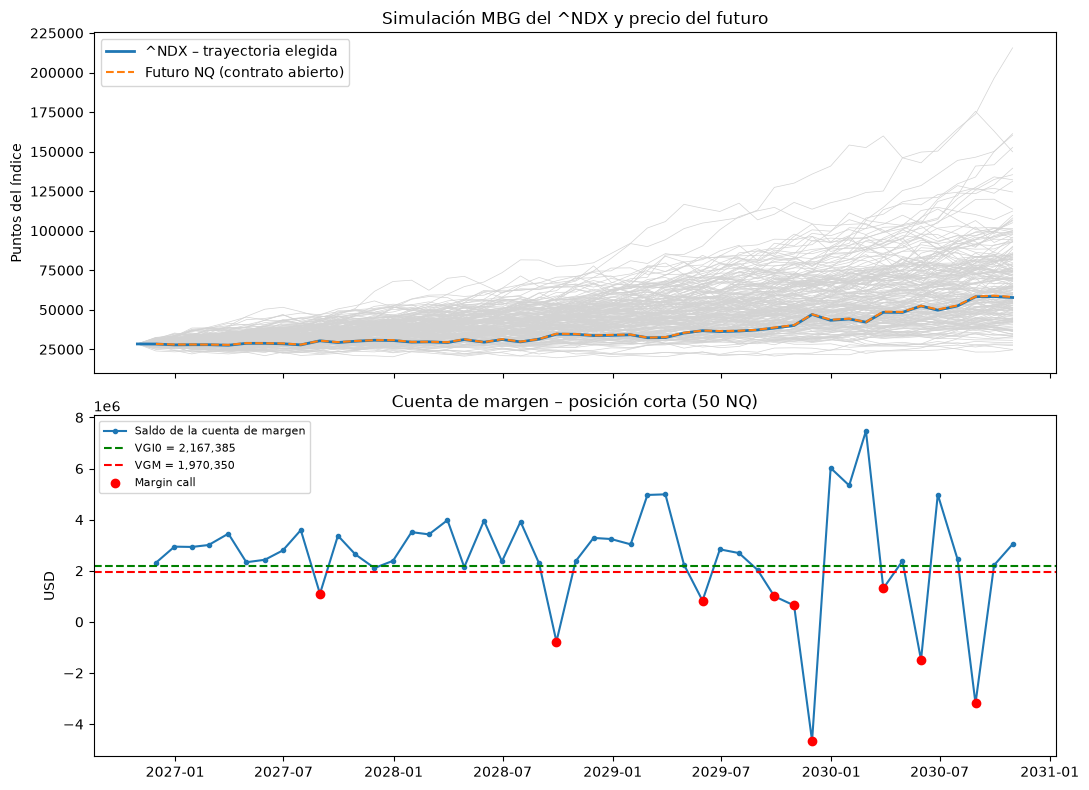

In [10]:
# 8.4 Gráfico: trayectoria simulada y cuenta de margen
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].plot(S_sim.index, S_sim.iloc[:, :200], color="lightgray", lw=0.5)          # 200 trayectorias de fondo
ax[0].plot(S.index, S, color="tab:blue", lw=2, label="^NDX – trayectoria elegida")
ax[0].plot(cuenta["Fecha"], cuenta["F final"], color="tab:orange", lw=1.5, ls="--", label="Futuro NQ (contrato abierto)")
ax[0].set_ylabel("Puntos del índice"); ax[0].legend(); ax[0].set_title("Simulación MBG del ^NDX y precio del futuro")
ax[1].plot(cuenta["Fecha"], cuenta["Saldo margen"], marker="o", ms=3, label="Saldo de la cuenta de margen")
ax[1].axhline(VGI0, color="green", ls="--", label=f"VGI0 = {VGI0:,.0f}")
ax[1].axhline(VGM, color="red", ls="--", label=f"VGM = {VGM:,.0f}")
mc_f = cuenta[cuenta["Margin call"]]
ax[1].scatter(mc_f["Fecha"], mc_f["Saldo margen"], color="red", zorder=3, label="Margin call")
ax[1].set_ylabel("USD"); ax[1].legend(fontsize=8); ax[1].set_title("Cuenta de margen – posición corta (50 NQ)")
plt.tight_layout()
fig.savefig(RAIZ / "outputs" / "figures" / "cuenta_margen_mensual.png", dpi=150)
plt.show()

**Interpretación:**

- **Escenario simulado:** En la trayectoria representativa mediana de 10,000 trayectorias el índice ^NDX pasa de 28,385 a 57,748 puntos en 4 años, es decir, se duplica. Es coherente con una tendencia histórica del 19.5% anual apróximadamente. El rango de las simulaciones es bastante amplio, por lo que una sola trayectoria no basta para concluir sobre el riesgo y las 10,000 se usan en los posteriores puntos 10 y 11.

- **Resultado de la posición corta:** 
    - Como el mercado sube, el corto pierde "sentido", el P&G acumulado es de **−USD 23.85 M**. Esta pérdida no es fracaso de la cobertura, es que en nuestro caso la valorización de la cartera de acciones. La cobertura cumple su función, que es fijar el resultado sistemático, y lo hace renunciando a la subida protegiendo la cartera de una caída.

- **Margin calls:** Hay **9 llamados en 48 meses** (en 8 de los 16 trimestres), con un total repuesto de **USD 24.72 M**. Están en los meses alcistas fuertes y aumentan al final del tiempo de la inversión. La razón se debe a que fijamos constantemente el rango entre *MI* y *MM* en USD apróximadamente USD 197 mil y mientras que el precio del índice se duplica, confirmamos lo anticipado en el paso 7.2 (el costo real de la cobertura corta es de **liquidez**, porque hay que tener caja disponible para reponer el margen en los meses buenos).

- **Roll-over:** El contrato cambia cada 3 meses, al cierre de noviembre, febrero, mayo y agosto.

## Punto 9 – Roll-over trimestral, riesgo de base y costos (R11 – 10 %)

## Punto 10 – Valor esperado de la cobertura trimestral y tasa libre de riesgo (R12 – 7 %)

## Punto 11 – Rendimiento y valor esperado mensual: 3 enfoques y dividendos (R13 – 6 %)

## Punto 12 – Sensibilidad a la beta: β = 0,6 y β = 1,5 (R14 – 6 %)